# Part 2 · The code: LoRA for a pretrained ViT

CS701 · W10 tutorial · TA Zichen

Open in Colab: **File → Save a copy in Drive** first.
We adapt one pretrained ViT to a small new dataset in three ways: linear probe, full fine-tuning and LoRA.
Run the cells from top to bottom. Each training cell takes about one minute on a free Colab T4.

## 2.1 Setup

Use a GPU. In Colab, select **Runtime → Change runtime type → T4 GPU**.
The first cell sets where the data comes from.

In [1]:
DATA_URL = "https://huggingface.co/datasets/doem1997/cs701-w10-lora-data/resolve/main/w10_data.zip"
ZIP_SHA256 = "d7d03d58b681e7000ed01c7efd083a2986cea0a09ee4ba340d8679a694cf5b55"  # checks the download
LOCAL_ZIP = "w10_data.zip"  # if this file exists and is correct, the notebook does not download
SEED = 42

In [2]:
!pip install -q timm

In [3]:
import copy, hashlib, os, random, time, urllib.request, warnings, zipfile
import matplotlib.pyplot as plt
import numpy as np
import timm
import torch
import torchvision as tv
from PIL import Image
from torch import nn

In [4]:
assert torch.cuda.is_available(), "No GPU. In Colab: Runtime > Change runtime type > T4 GPU."
device = "cuda"
# T4: no real bfloat16, so we use float16 + a gradient scaler. Newer GPUs: bfloat16.
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
# float16: the gradient scaler may skip the first step. This is normal, so we hide the warning.
warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")
print(torch.cuda.get_device_name(), "| autocast:", AMP_DTYPE, "| torch", torch.__version__, "| timm", timm.__version__)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

NVIDIA RTX PRO 6000 Blackwell Server Edition | autocast: torch.bfloat16 | torch 2.9.0+cu128 | timm 1.0.24


## 2.2 Data

The data is a small part of EuroSAT: satellite photos of land use, 10 classes, 64 × 64 pixels.
We train on 20 images per class (200 images) and test on 100 per class (1,000 images).
EuroSAT: Helber et al., 2019, MIT licence.

In [5]:
def sha256(path):
    return hashlib.sha256(open(path, "rb").read()).hexdigest()


if not os.path.exists(LOCAL_ZIP) or sha256(LOCAL_ZIP) != ZIP_SHA256:
    urllib.request.urlretrieve(DATA_URL, LOCAL_ZIP)  # download (again, if the old file is broken)
assert sha256(LOCAL_ZIP) == ZIP_SHA256, "The download is broken. Run this cell again."
zipfile.ZipFile(LOCAL_ZIP).extractall("w10_data")
classes = open("w10_data/classes.txt").read().split()  # index = line number
print(len(classes), "classes:", classes)

10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [6]:
mean = std = (0.5, 0.5, 0.5)  # the values this ViT checkpoint uses
train_tf = tv.transforms.Compose([
    tv.transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),  # 64 px -> 224 px, random crop
    tv.transforms.RandomHorizontalFlip(),
    tv.transforms.ToTensor(), tv.transforms.Normalize(mean, std)])
test_tf = tv.transforms.Compose([
    tv.transforms.Resize((224, 224)),
    tv.transforms.ToTensor(), tv.transforms.Normalize(mean, std)])

train_set = tv.datasets.ImageFolder("w10_data/train", train_tf)
test_set = tv.datasets.ImageFolder("w10_data/test", test_tf)
assert train_set.classes == test_set.classes == classes
print(len(train_set), "training images |", len(test_set), "test images")
test_loader = torch.utils.data.DataLoader(test_set, batch_size=128, num_workers=2)


def train_loader():  # a new generator with the same seed: same batches and crops for every method
    g = torch.Generator().manual_seed(SEED)
    return torch.utils.data.DataLoader(train_set, batch_size=32, shuffle=True, drop_last=True,
                                       num_workers=2, persistent_workers=True, generator=g)

200 training images | 1000 test images


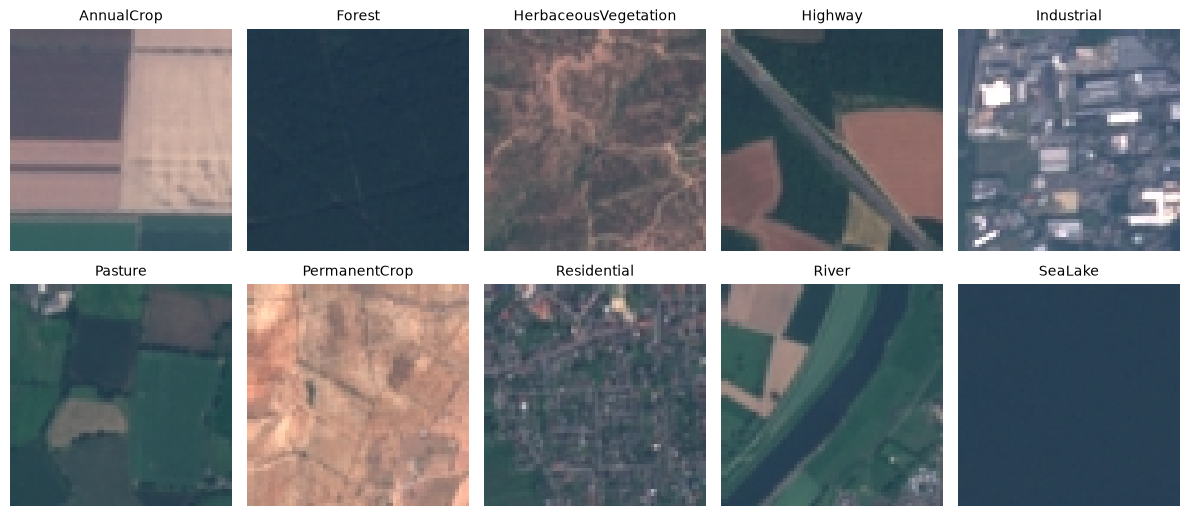

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
for c, ax in enumerate(axes.flat):
    path = next(p for p, label in train_set.samples if label == c)  # first training image of class c
    ax.imshow(Image.open(path))
    ax.set_title(classes[c], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2.3 The pretrained ViT

We use ViT-B/16, pretrained on ImageNet-21k (`timm` name `vit_base_patch16_224.augreg_in21k`).
`new_vit()` loads it with a new, random head for our 10 classes.
The seed makes the head the same for every method.

In [8]:
def new_vit():
    seed_everything()  # same random head for every method
    return timm.create_model("vit_base_patch16_224.augreg_in21k", pretrained=True, num_classes=len(classes))


def n_weights(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


vit = new_vit().eval()  # the pretrained model: we keep it as a reference
N_VIT = n_weights(vit)
print(f"ViT-B/16 with a 10-class head: {N_VIT:,} weights ({N_VIT / 1e6:.1f} M)")
print(vit.blocks[0].attn)

ViT-B/16 with a 10-class head: 85,806,346 weights (85.8 M)
Attention(
  (qkv): Linear(in_features=768, out_features=2304, bias=True)
  (q_norm): Identity()
  (k_norm): Identity()
  (attn_drop): Dropout(p=0.0, inplace=False)
  (norm): Identity()
  (proj): Linear(in_features=768, out_features=768, bias=True)
  (proj_drop): Dropout(p=0.0, inplace=False)
)


## 2.4 One train function for every method

Every method uses the same `train()` and `evaluate()`.
Only two things change: which weights are trainable, and the learning rate (LR).
`train()` uses AdamW, a one-cycle LR schedule with 10 % warm-up, batch 32 and 20 epochs.

In [9]:
@torch.no_grad()
def evaluate(model):
    model.eval()
    correct = 0
    for x, y in test_loader:
        with torch.autocast("cuda", AMP_DTYPE):
            pred = model(x.to(device)).argmax(1)
        correct += (pred.cpu() == y).sum().item()
    return correct / len(test_set)

In [10]:
def train(model, lr, epochs=20):
    seed_everything()
    loader = train_loader()
    model.to(device).train()
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(loader), pct_start=0.1)
    scaler = torch.amp.GradScaler(enabled=(AMP_DTYPE == torch.float16))  # needed for float16 only
    hist = {"lr": lr, "epochs": epochs, "trainable": n_weights(model, True), "total": n_weights(model), "loss": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        total = 0.0
        for x, y in loader:
            with torch.autocast("cuda", AMP_DTYPE):
                loss = nn.functional.cross_entropy(model(x.to(device)), y.to(device))
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            total += loss.item()
        hist["loss"].append(round(total / len(loader), 4))
        if epoch % 5 == 0:
            print(f"epoch {epoch:2d}/{epochs}   train loss {hist['loss'][-1]:.3f}")
    hist["seconds"] = round(time.time() - start, 1)
    hist["accuracy"] = evaluate(model)
    print(f"train time {hist['seconds']} s | test accuracy {hist['accuracy']:.1%}")
    return hist


results = {}  # one entry per method

## 2.5 Method 1: linear probe

Freeze the whole pretrained ViT. Train only the new head.
Your numbers can differ from the slides by 1–2 points: Colab's T4 uses float16.

In [11]:
lp_model = new_vit()  # a new model: you can run this cell again
lp_model.requires_grad_(False)  # freeze everything
lp_model.head.requires_grad_(True)  # the head trains
n = n_weights(lp_model, True)
print(f"trainable weights: {n:,} ({n / N_VIT:.3%} of the ViT)")
results["linear probe"] = train(lp_model, lr=1e-2)

trainable weights: 7,690 (0.009% of the ViT)


epoch  5/20   train loss 0.132


epoch 10/20   train loss 0.043


epoch 15/20   train loss 0.007


epoch 20/20   train loss 0.002


train time 3.7 s | test accuracy 89.2%


## 2.6 Method 2: full fine-tuning

Train all weights of the ViT and the head. Full fine-tuning needs a small LR: 1e-4.

In [12]:
fft_model = new_vit()  # all weights are trainable by default
n = n_weights(fft_model, True)
print(f"trainable weights: {n:,} ({n / N_VIT:.0%} of the ViT)")
results["full fine-tuning"] = train(fft_model, lr=1e-4)

trainable weights: 85,806,346 (100% of the ViT)


epoch  5/20   train loss 0.102


epoch 10/20   train loss 0.033


epoch 15/20   train loss 0.001


epoch 20/20   train loss 0.001


train time 6.3 s | test accuracy 91.7%


Full fine-tuning changes every weight. So each new task needs its own full copy of the model.

In [13]:
torch.save(fft_model.state_dict(), "fft_task.pt")
fft_mb = os.path.getsize("fft_task.pt") / 1e6
print(f"full fine-tuning: save {fft_mb:.1f} MB per task")

full fine-tuning: save 343.3 MB per task


## 2.7 Write LoRA

LoRA adds a small trainable branch to a frozen layer W: y = W x + (α / r) · B A x.
A (`down`) maps the input (768 numbers) to r numbers.
B (`up`) maps the r numbers to the output (2,304 numbers for qkv).
B starts at zero, so at step 0 the branch adds nothing.

In [14]:
class LoRA(nn.Module):
    """y = W x + (alpha / r) * B A x, where W is the wrapped (frozen) layer."""

    def __init__(self, base: nn.Linear, rank=8, alpha=16):
        super().__init__()
        self.base = base
        self.down = nn.Linear(base.in_features, rank, bias=False)  # A
        self.up = nn.Linear(rank, base.out_features, bias=False)  # B
        nn.init.zeros_(self.up.weight)  # B = 0: training starts from exactly the pretrained layer
        self.scale = alpha / rank

    def forward(self, x):
        return self.base(x) + self.scale * self.up(self.down(x))

## 2.8 Put LoRA into the ViT

We wrap `attn.qkv` in each of the 12 blocks with LoRA (r = 8, α = 16).
The ViT is frozen. A, B and the head train.

In [15]:
def add_lora(model, rank=8, alpha=16):
    model.requires_grad_(False)  # freeze the pretrained ViT
    for block in model.blocks:
        block.attn.qkv = LoRA(block.attn.qkv, rank, alpha)  # new A and B are trainable
    model.head.requires_grad_(True)  # the new head trains too
    return model


fresh_lora = add_lora(new_vit())  # a new LoRA model; we never train this one
qkv = fresh_lora.blocks[0].attn.qkv
w_qkv, a_qkv, b_qkv = qkv.base.weight.numel(), qkv.down.weight.numel(), qkv.up.weight.numel()
print(qkv)
print(f"one qkv layer: W {w_qkv:,} weights (frozen) | A + B {a_qkv + b_qkv:,} weights ({(a_qkv + b_qkv) / w_qkv:.1%} of W)")

LoRA(
  (base): Linear(in_features=768, out_features=2304, bias=True)
  (down): Linear(in_features=768, out_features=8, bias=False)
  (up): Linear(in_features=8, out_features=2304, bias=False)
)
one qkv layer: W 1,769,472 weights (frozen) | A + B 24,576 weights (1.4% of W)


**Check 1.** B = 0, so a new LoRA model must give the same output as the pretrained ViT.
The seed is the same, so the head is the same too.

In [16]:
x_check = next(iter(test_loader))[0].to(device)  # 128 test images
vit.to(device)
fresh_lora.to(device).eval()
with torch.no_grad():
    fresh_diff = (fresh_lora(x_check) - vit(x_check)).abs().max().item()
print("max |logit difference|, new LoRA model vs pretrained ViT:", fresh_diff)

max |logit difference|, new LoRA model vs pretrained ViT: 0.0


## 2.9 Method 3: LoRA

LoRA needs a larger LR than full fine-tuning. We use 3e-3.

In [17]:
lora_model = add_lora(new_vit())  # a new model: you can run this cell again
n = n_weights(lora_model, True)
print(f"trainable weights: {n:,} ({n / N_VIT:.2%} of the ViT)")
results["LoRA"] = train(lora_model, lr=3e-3)

trainable weights: 302,602 (0.35% of the ViT)


epoch  5/20   train loss 0.104


epoch 10/20   train loss 0.065


epoch 15/20   train loss 0.017


epoch 20/20   train loss 0.003


train time 5.0 s | test accuracy 92.3%


For each new task, LoRA saves only A, B and the head. The pretrained ViT is shared by all tasks.

In [18]:
lora_weights = {name: p for name, p in lora_model.named_parameters() if p.requires_grad}  # A, B, head
torch.save(lora_weights, "lora_task.pt")
lora_mb = os.path.getsize("lora_task.pt") / 1e6
print(f"LoRA: save {lora_mb:.2f} MB per task | full fine-tuning: {fft_mb:.1f} MB")

LoRA: save 1.22 MB per task | full fine-tuning: 343.3 MB


## 2.10 Merge, and switch off

**Check 2.** After training, we merge the branch into W: W' = W + (α / r) · B A.
The merged model is a normal ViT again, so inference has no extra cost.

In [19]:
def merge(lora_layer):
    merged = copy.deepcopy(lora_layer.base)
    with torch.no_grad():
        merged.weight += lora_layer.scale * lora_layer.up.weight @ lora_layer.down.weight
    return merged


merged_model = copy.deepcopy(lora_model)
for block in merged_model.blocks:
    block.attn.qkv = merge(block.attn.qkv)

In [20]:
lora_model.eval()
merged_model.eval()
with torch.no_grad():
    merge_diff = (merged_model(x_check) - lora_model(x_check)).abs().max().item()
merged_acc, merged_weights = evaluate(merged_model), n_weights(merged_model)
print("max |logit difference|, merged vs LoRA:", merge_diff)
print(f"weights: merged {merged_weights:,} | pretrained ViT {N_VIT:,}")
print(f"test accuracy: merged {merged_acc:.1%} | LoRA {results['LoRA']['accuracy']:.1%}")

max |logit difference|, merged vs LoRA: 4.57763671875e-05
weights: merged 85,806,346 | pretrained ViT 85,806,346
test accuracy: merged 92.3% | LoRA 92.3%


**Check 3.** When the scale is 0, the branch is off. Then the ViT body is the pretrained ViT again.
We compare the features before the head, because the head is new.

In [21]:
old_scale = lora_model.blocks[0].attn.qkv.scale
for block in lora_model.blocks:
    block.attn.qkv.scale = 0.0  # branch off
with torch.no_grad():
    off_diff = (lora_model.forward_features(x_check) - vit.forward_features(x_check)).abs().max().item()
print("max |feature difference|, LoRA off vs pretrained ViT:", off_diff)
for block in lora_model.blocks:
    block.attn.qkv.scale = old_scale  # branch on again

max |feature difference|, LoRA off vs pretrained ViT: 0.0


## 2.11 Compare the three methods

Same data, same seed, same `train()`. Only the trainable weights and the LR change.

In [22]:
print(f"{'method':<18}{'trainable weights':>20}{'% of ViT':>10}{'test acc':>10}{'train s':>9}")
for name, h in results.items():
    print(f"{name:<18}{h['trainable']:>20,}{h['trainable'] / N_VIT:>10.2%}{h['accuracy']:>10.1%}{h['seconds']:>9.0f}")

method               trainable weights  % of ViT  test acc  train s
linear probe                     7,690     0.01%     89.2%        4
full fine-tuning            85,806,346   100.00%     91.7%        6
LoRA                           302,602     0.35%     92.3%        5


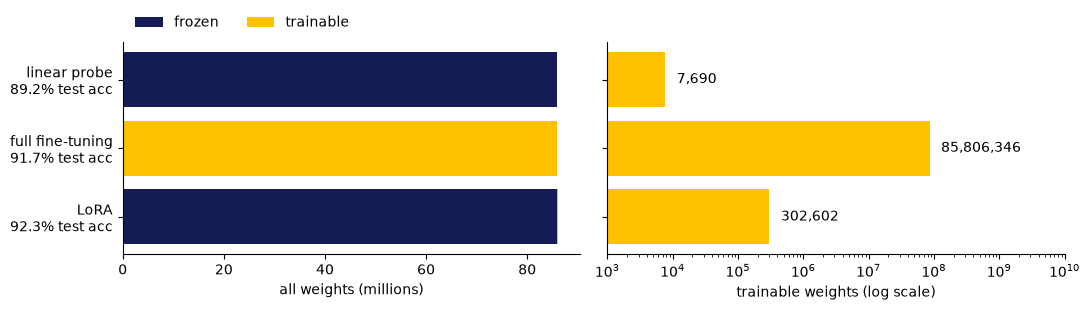

In [23]:
NAVY, AMBER = "#151C55", "#FFC000"  # frozen, trainable
names = list(results)
labels = [f"{k}\n{results[k]['accuracy']:.1%} test acc" for k in names]
trainable = np.array([results[k]["trainable"] for k in names])
frozen = np.array([results[k]["total"] for k in names]) - trainable
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
ax1.barh(labels, frozen / 1e6, color=NAVY, label="frozen")
ax1.barh(labels, trainable / 1e6, left=frozen / 1e6, color=AMBER, label="trainable")
ax1.set_xlabel("all weights (millions)")
ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
ax2.barh(labels, trainable, color=AMBER)
ax2.set_xscale("log")
ax2.set_xlim(1e3, 1e10)
ax2.set_xlabel("trainable weights (log scale)")
for i, n in enumerate(trainable):
    ax2.text(n * 1.5, i, f"{n:,}", va="center")
ax1.invert_yaxis()
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2.12 Live ablation: the LR of LoRA

What happens if LoRA uses the LR of full fine-tuning (1e-4)?
We train one new LoRA model with LR 1e-4 and compare with the 3e-3 run above.

In [24]:
lora_slow = add_lora(new_vit())
lora_slow_hist = train(lora_slow, lr=1e-4)
print(f"LoRA, LR 1e-4: {lora_slow_hist['accuracy']:.1%} | LoRA, LR 3e-3: {results['LoRA']['accuracy']:.1%}")

epoch  5/20   train loss 1.952


epoch 10/20   train loss 0.924


epoch 15/20   train loss 0.579


epoch 20/20   train loss 0.482


train time 5.0 s | test accuracy 73.7%
LoRA, LR 1e-4: 73.7% | LoRA, LR 3e-3: 92.3%


## 2.13 Try at home

- Change the rank: `add_lora(new_vit(), rank=4, alpha=8)` or `rank=16, alpha=32`.
- Put LoRA also on `attn.proj`, or on `mlp.fc1` and `mlp.fc2`.
- Each time, look at the trainable weights and the test accuracy.

# Part 3 · Your assignment

Open `sarbench/adapters.py` in your assignment code. Its `LoRA` class is the same as the class above.
`add_adapters` puts LoRA into `attn.qkv` and `attn.proj` of every block (rank 16, α = 32).

In [25]:
# For the TA only: save the numbers for the slides. It does nothing in Colab, so you can skip it.
if os.environ.get("W10_RESULTS_JSON"):
    import json
    run = dict(gpu=torch.cuda.get_device_name(), autocast=str(AMP_DTYPE), vit_weights=N_VIT, methods=results,
               lr_ablation={"1e-4": lora_slow_hist, "3e-3": results["LoRA"]}, fft_save_mb=fft_mb, lora_save_mb=lora_mb,
               qkv_layer=dict(W=w_qkv, A=a_qkv, B=b_qkv, lora=a_qkv + b_qkv),
               checks=dict(fresh_diff=fresh_diff, merge_diff=merge_diff, merged_acc=merged_acc,
                           merged_weights=merged_weights, off_diff=off_diff))
    json.dump(run, open(os.environ["W10_RESULTS_JSON"], "w"), indent=1)